<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI — Vector Gateway Interface" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Haybarn](https://query.farm/products/haybarn/) · [Guide](README.md)

# 01 · Follow a funding gap across venues

Imagine seeing substantially higher funding for the same asset on one venue than
another. Is that a meaningful difference, a mismatch in units, or missing data?
We will follow that question from coverage through contracts to settled rates,
then inspect the provenance of the price snapshot.

The explanatory text describes the method. Numerical findings and chart labels
are generated from your selected results, so changing the asset, dates or data
mode also changes the story's evidence. Annualization puts rates on a common scale;
it is not a forecast of returns.

## Choose the run

Replay supports **BTC**, with any analysis subwindow inside **10 Nov 2026 00:00 →
13 Nov 2026 00:00 UTC**. The end is exclusive. We fetch the complete recording and
filter it locally. In live mode, `None` selects the last three complete UTC days;
other assets depend on venue availability.

Edit the visible parameters, then **Restart Kernel → Run All**. Saved outputs are a replay run.
`DATA_MODE = "live"` uses public APIs with recent default dates; there is no fallback to fixtures.
[Setup instructions](README.md#run-in-vs-code) are separate from the analysis.

The visible connection SQL downloads the pinned **v0.1.5** worker through `uvx`. No local worker build or path configuration is needed. The selected data mode configures its fixture and clock environment before connection.


In [1]:
DATA_MODE = "replay"          # "replay" or "live"
ASSET = "BTC"
START_DATE = None             # Inclusive ISO date/time, e.g. "2026-11-12"
END_DATE = None               # Exclusive ISO date/time, e.g. "2026-11-13"

In [2]:
# Python setup · expand to inspect environment and shared presentation helpers.
from pathlib import Path
import os
import sys
os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = next(
    p for p in (Path.cwd(), Path.cwd() / "notebooks", *Path.cwd().parents)
    if (p / "notebook_support.py").is_file() and (p / "fixtures/venues").is_dir()
)
sys.path.insert(0, str(NOTEBOOK_DIR))
import haybarn
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.ticker import FuncFormatter
from IPython.display import display
from notebook_support import (
    ASK, BID, COLORS, VENUE_NAMES, finite_numbers, finish_chart, make_run,
    money, number, prose, require_rows, set_theme, sql_text,
)
run = make_run(DATA_MODE, NOTEBOOK_DIR)
set_theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

def chart(fig, title, subtitle, source=None):
    finish_chart(fig, title, subtitle, source or run.source)

Tip: You may define configurations in /Users/rusty/Development/vgi-perps/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-perps/notebooks/pyproject.toml.

In [3]:
asset = run.validate_asset(ASSET)
window = run.window("funding", START_DATE, END_DATE)
run.badge(funding=window)

**REPLAY · local recorded responses**  
Recorded worker clock: **2026-11-13 01:20:00 UTC**. Venue requests stay local.  
**Funding:** 10 Nov 2026 00:00 → 13 Nov 2026 00:00 UTC (end excluded)

In [4]:
%%sql
-- uvx fetches the pinned worker release; no local worker installation is needed.
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'perps' (TYPE vgi, LOCATION 'uvx --from git+https://github.com/Query-farm/vgi-perps@v0.1.5 vgi-perps-worker');
SELECT extension_name, extension_version, loaded
FROM duckdb_extensions() WHERE extension_name = 'vgi';

,extension_name,extension_version,loaded
0,vgi,e75482339d,True


## Who can actually answer the question?

An unreachable venue and a venue reporting zero funding mean different things.
`venues()` returns access failures as rows. We retain those diagnostics and pair
them with static capabilities, because a healthy venue can still lack historical data.

In [5]:
%%sql health <<
SELECT venue, venue_type, status, instrument_count, last_error
FROM perps.main.venues() ORDER BY venue;

In [6]:
display(health)
ok = health.loc[health.status == "ok", "venue"].tolist()
failed = health.loc[health.status == "error", "venue"].tolist()
prose(f"**Coverage for this run:** {len(ok)} venues responded; {len(failed)} returned errors. "
      + ("Unavailable: " + ", ".join(failed) + ". " if failed else "")
      + ("Counts describe trimmed recordings, not exchange-wide listings." if run.replay else "These are live probes; later requests can still fail."))

,venue,venue_type,status,instrument_count,last_error
0,binance,offshore,error,<NA>,VenueError: binance (ccxt binanceusdm) fetch_m...
1,bitnomial,us_regulated,ok,6,None
2,bybit,offshore,error,<NA>,VenueError: bybit (ccxt bybit) fetch_markets f...
3,coinbase,us_regulated,ok,8,None
4,hyperliquid,offshore,ok,11,None
5,kalshi,us_regulated,ok,14,None
6,og,us_regulated,ok,3,None


**Coverage for this run:** 5 venues responded; 2 returned errors. Unavailable: binance, bybit. Counts describe trimmed recordings, not exchange-wide listings.

In [7]:
%%sql coverage <<
SELECT venue, capability, support, auth_required
FROM perps.main.capabilities()
WHERE capability IN ('funding_history', 'marks', 'order_book', 'candles', 'trades')
ORDER BY venue, capability;

findfont: Failed to find font weight semibold for Arial, now using 700.


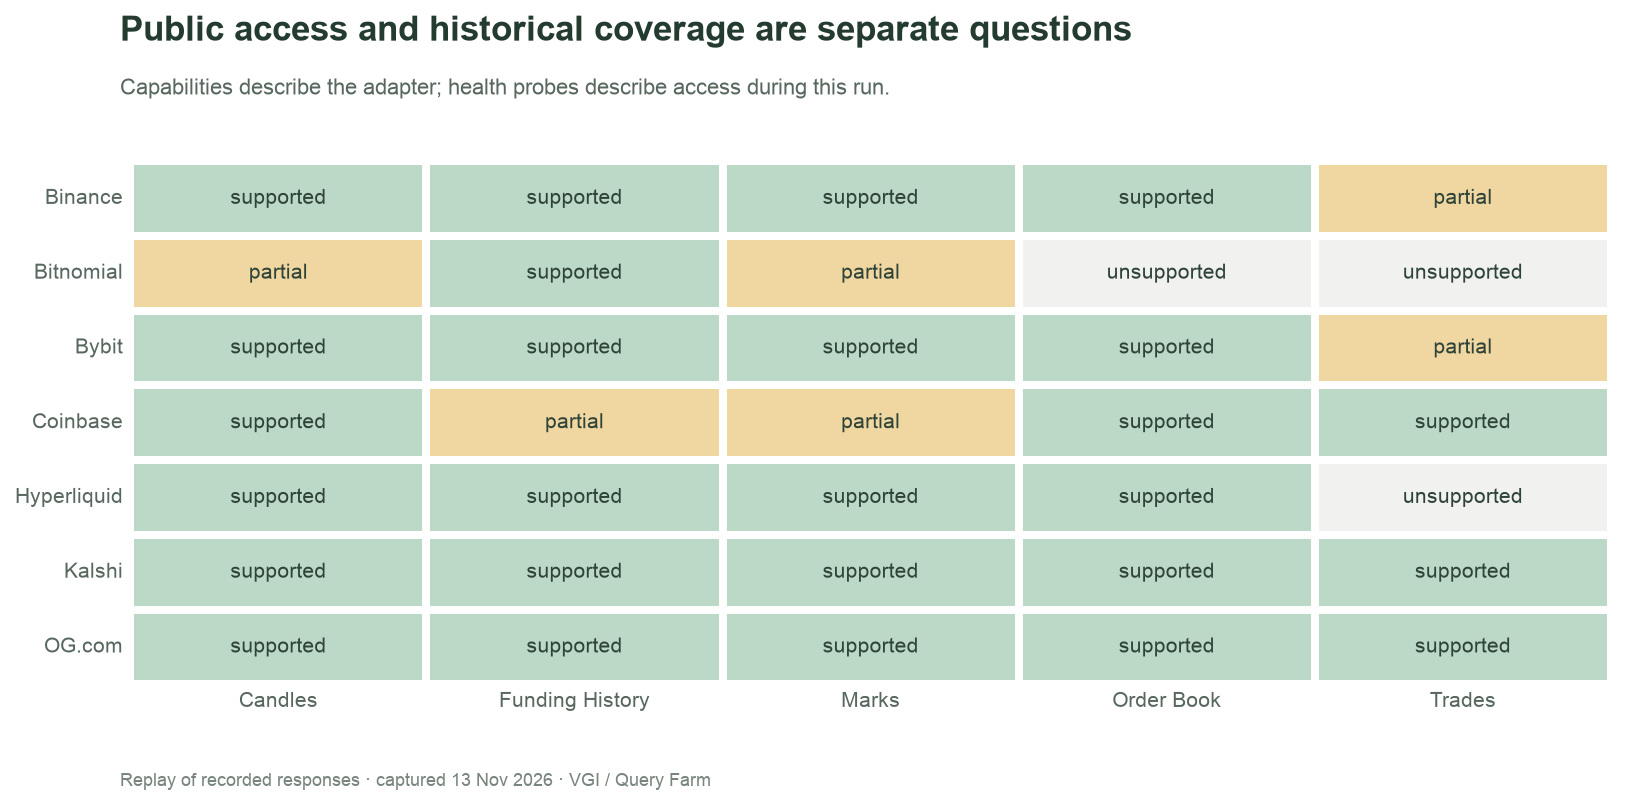

In [8]:
matrix = coverage.pivot(index="venue", columns="capability", values="support")
levels = {"unsupported": 0, "partial": 1, "supported": 2}
fig, ax = plt.subplots(figsize=(11, 5.3))
sns.heatmap(matrix.map(levels.get), annot=matrix, fmt="", ax=ax,
            cmap=ListedColormap(["#F1F2EF", "#F0D6A1", "#BCD9C8"]),
            vmin=0, vmax=2, cbar=False, linewidths=3, linecolor="white",
            annot_kws={"fontsize": 10, "color": "#2F4438"})
ax.set_xticklabels([x.replace("_", " ").title() for x in matrix.columns], rotation=0)
ax.set_yticklabels([VENUE_NAMES.get(x, x) for x in matrix.index], rotation=0)
ax.set(xlabel="", ylabel=""); ax.tick_params(length=0)
chart(fig, "Public access and historical coverage are separate questions",
      "Capabilities describe the adapter; health probes describe access during this run.")

## Put contracts and payment schedules on a common scale

One contract can represent a different amount of the underlying on each venue.
Inspect `contract_size` and `quote_ccy` before comparing sizes. Notional is
`contracts × contract_size × price`; the worker does not convert USD and USDC.
Keep `(venue, symbol)` as the contract key so multiple contracts remain distinguishable.

Funding requires the same care. A decimal rate of `0.0001` is one basis point per
interval. Simple annualization is `rate_per_interval × 8760 / interval_hours`.
Positive rates mean longs pay shorts.

In [9]:
%%sql
CREATE OR REPLACE TABLE contracts AS
SELECT venue, symbol, underlying, quote_ccy, contract_size, funding_interval_hours
FROM perps.main.instruments(underlying := {{ sql_text(asset) }});
SELECT * FROM contracts ORDER BY venue, symbol;

,venue,symbol,underlying,quote_ccy,contract_size,funding_interval_hours
0,bitnomial,PBTCUCZ50,BTC,USD,0.0100,8.0
1,bitnomial,PBTCURZ50,BTC,USD,0.0001,8.0
2,coinbase,BIP-20DEC30-CDE,BTC,USD,0.0100,1.0
3,hyperliquid,BTC,BTC,USDC,1.0000,1.0
4,kalshi,KXBTCPERP,BTC,USD,0.0001,8.0
5,og,BTC-USD-PERP,BTC,USD,1.0000,8.0


## Compare settled observations in the selected interval

We fetch the source window once and then apply your half-open analysis interval.
Replay can therefore support date experiments without inventing new recordings.
`is_final` keeps in-progress estimates out of the historical average.

Read settlement counts, covered hours and first/last timestamps beside the mean.
Equal covered hours can still represent offset settlement schedules.

In [10]:
%%sql summary <<
CREATE OR REPLACE TABLE source_funding AS
SELECT * FROM perps.main.funding(
    underlying := {{ sql_text(asset) }},
    start_date := TIMESTAMPTZ {{ sql_text(window.fetch_start) }},
    end_date := TIMESTAMPTZ {{ sql_text(window.fetch_end) }}
) WHERE is_final;
CREATE OR REPLACE TABLE selected_funding AS
SELECT * FROM source_funding
WHERE funding_time >= TIMESTAMPTZ {{ sql_text(window.start) }}
  AND funding_time < TIMESTAMPTZ {{ sql_text(window.end) }};
CREATE OR REPLACE TABLE funding_summary AS
SELECT venue, symbol, count(*) AS settlements,
       min(funding_time) AS first_settlement, max(funding_time) AS last_settlement,
       sum(interval_hours) AS observed_hours, 100 * avg(rate_annualized) AS mean_annualized_pct
FROM selected_funding GROUP BY venue, symbol;
SELECT * FROM funding_summary ORDER BY mean_annualized_pct DESC, venue, symbol;

In [11]:
require_rows(summary, f"settled {asset} funding observations for {window.label}")
display(summary)
missing = sorted(set(health.venue) - set(summary.venue))
prose(f"The selected sample contains **{len(summary)} contracts across {summary.venue.nunique()} venues**, "
      f"with **{int(summary.settlements.sum())} settlements**. Covered hours range from "
      f"**{number(summary.observed_hours.min(), 0)} to {number(summary.observed_hours.max(), 0)}** per contract. "
      + ("No selected settlements were returned for " + ", ".join(missing) + "; this is not a zero rate." if missing else ""))
assert con.execute("SELECT bool_and(abs(rate_annualized - rate_per_interval * 8760 / interval_hours) < 1e-12) FROM selected_funding").fetchone()[0]

,venue,symbol,settlements,first_settlement,last_settlement,observed_hours,mean_annualized_pct
0,kalshi,KXBTCPERP,9,2026-11-10 05:00:00+00:00,2026-11-12 21:00:00+00:00,72.0,14.71157
1,bitnomial,PBTCUCZ50,9,2026-11-10 01:00:00+00:00,2026-11-12 17:00:00+00:00,72.0,10.95000
2,bitnomial,PBTCURZ50,9,2026-11-10 01:00:00+00:00,2026-11-12 17:00:00+00:00,72.0,10.95000
3,og,BTC-USD-PERP,9,2026-11-10 00:00:00+00:00,2026-11-12 16:00:00+00:00,72.0,10.95000
4,hyperliquid,BTC,72,2026-11-10 00:00:00+00:00,2026-11-12 23:00:00+00:00,72.0,8.64293


The selected sample contains **5 contracts across 4 venues**, with **108 settlements**. Covered hours range from **72 to 72** per contract. No selected settlements were returned for binance, bybit, coinbase; this is not a zero rate.

In [12]:
%%sql funding <<
SELECT venue, symbol, funding_time, 100 * rate_annualized AS annualized_pct
FROM selected_funding ORDER BY venue, symbol, funding_time;

findfont: Failed to find font weight semibold for Arial, now using 700.


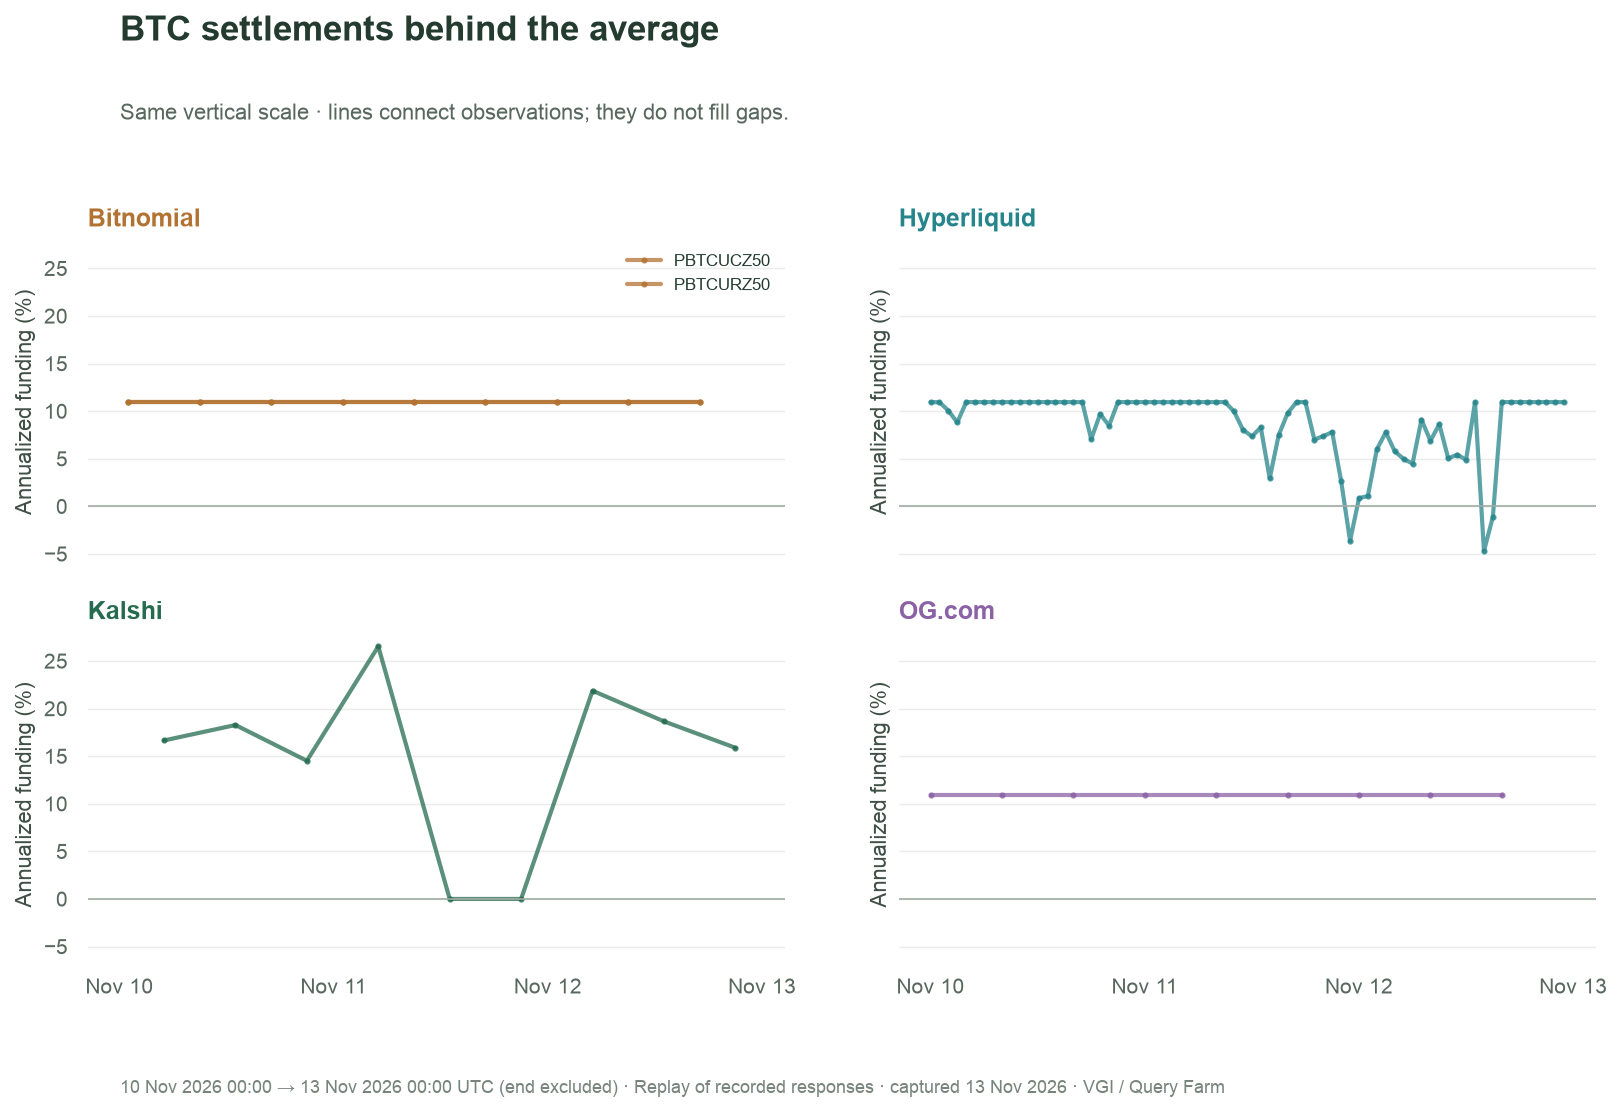

In [13]:
venues = sorted(funding.venue.unique())
fig, axes = plt.subplots((len(venues)+1)//2, 2, figsize=(11, 3.2*((len(venues)+1)//2)+1),
                          sharex=True, sharey=True, squeeze=False)
for ax, venue in zip(axes.flat, venues):
    rows = funding[funding.venue == venue]
    for symbol, group in rows.groupby("symbol"):
        ax.plot(group.funding_time, group.annualized_pct, marker=".", markersize=4,
                color=COLORS[venue], alpha=0.75, label=symbol)
    ax.axhline(0, color="#A0ACA4", linewidth=0.8)
    ax.set_title(VENUE_NAMES[venue], color=COLORS[venue]); ax.set(xlabel="", ylabel="Annualized funding (%)")
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(minticks=3,maxticks=5))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d", tz="UTC"))
    ax.grid(axis="x", visible=False)
    if rows.symbol.nunique()>1: ax.legend(fontsize=8)
for ax in list(axes.flat)[len(venues):]: ax.set_visible(False)
chart(fig, f"{asset} settlements behind the average", "Same vertical scale · lines connect observations; they do not fill gaps.", window.label+" · "+run.source)

In [14]:
zeros = int(funding.annualized_pct.eq(0).sum())
negative = int(funding.annualized_pct.lt(0).sum())
prose(f"Across the selected contracts, **{zeros} settlements are zero and {negative} are negative**. "
      "Negative funding reverses the payment direction. The individual paths show whether a mean represents "
      "steady payments or a more variable history; overlapping lines can represent separate contracts.")

Across the selected contracts, **2 settlements are zero and 3 are negative**. Negative funding reverses the payment direction. The individual paths show whether a mean represents steady payments or a more variable history; overlapping lines can represent separate contracts.

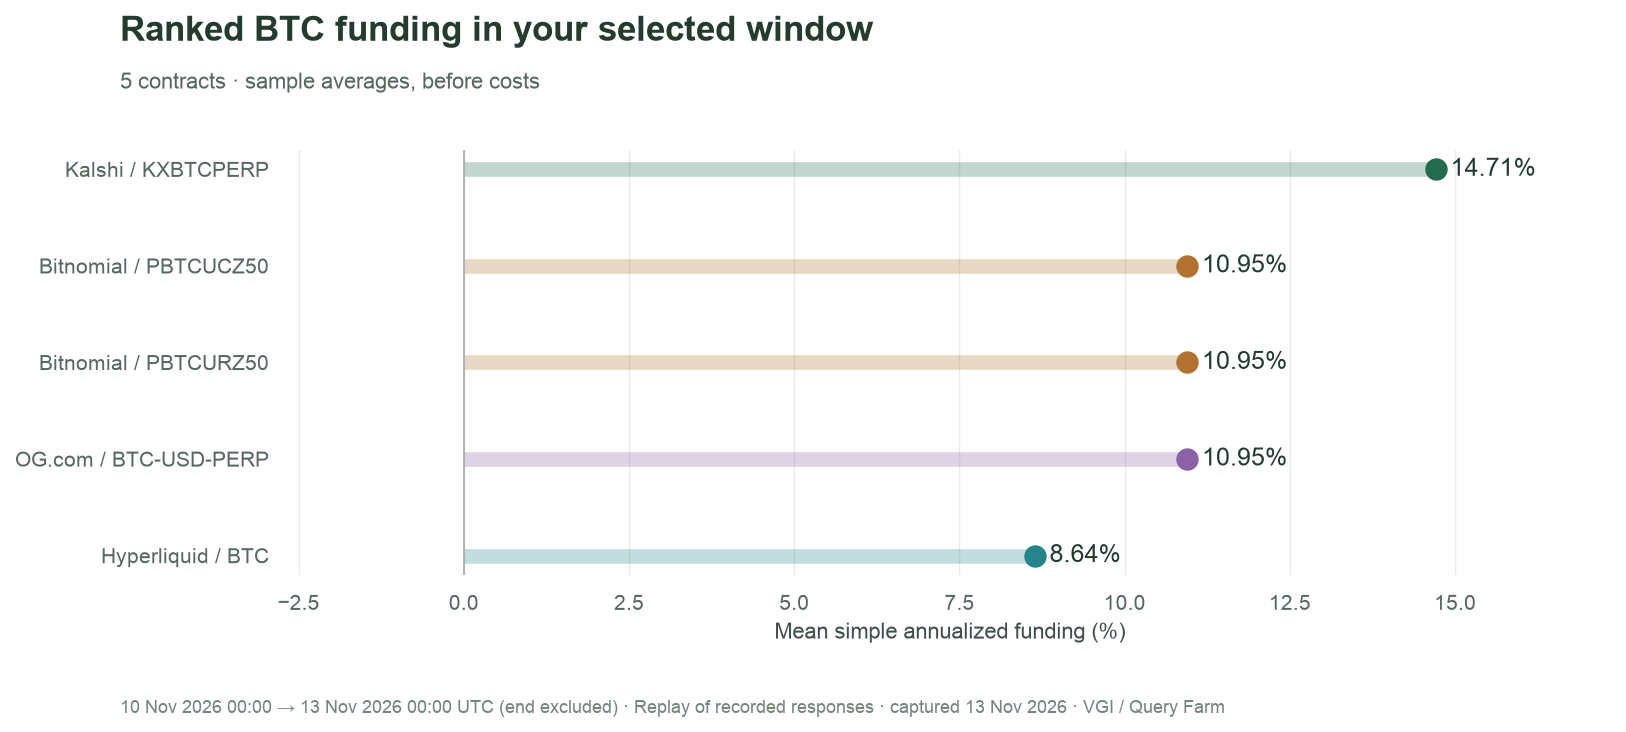

In [15]:
ranked = summary.sort_values(["mean_annualized_pct","venue","symbol"],ascending=[False,True,True]).reset_index(drop=True)
labels = ranked.venue.map(VENUE_NAMES)+" / "+ranked.symbol
fig, ax = plt.subplots(figsize=(11,max(4.8,0.45*len(ranked)+2)))
for i,row in ranked.iterrows():
    ax.hlines(i,0,row.mean_annualized_pct,color=COLORS[row.venue],alpha=0.28,linewidth=7)
    ax.scatter(row.mean_annualized_pct,i,color=COLORS[row.venue],s=95,zorder=3)
    ax.annotate(f"{row.mean_annualized_pct:.2f}%",(row.mean_annualized_pct,i),xytext=(7,0),textcoords="offset points",va="center")
ax.set_yticks(range(len(ranked)),labels); ax.invert_yaxis(); ax.margins(x=0.18)
ax.axvline(0,color="#A0ACA4",linewidth=0.8); ax.grid(axis="y",visible=False)
ax.set(xlabel="Mean simple annualized funding (%)",ylabel="")
chart(fig,f"Ranked {asset} funding in your selected window",f"{len(ranked)} contracts · sample averages, before costs",window.label+" · "+run.source)

In [16]:
top = ranked.iloc[0]
other = ranked[ranked.venue != top.venue]
if not other.empty:
    low = other.iloc[-1]
    gap = top.mean_annualized_pct-low.mean_annualized_pct
    prose(f"**{VENUE_NAMES[top.venue]} / {top.symbol} averages {top.mean_annualized_pct:.2f}%**, compared with "
          f"**{low.mean_annualized_pct:.2f}% for {VENUE_NAMES[low.venue]} / {low.symbol}**. "
          f"That is a **{gap:.2f} percentage point** gap on a simple annualized scale. "
          "It is a historical comparison, not a return earned over the analysis window.")
else:
    prose("Only one venue has selected funding observations. A cross-venue gap is unavailable.")

**Kalshi / KXBTCPERP averages 14.71%**, compared with **8.64% for Hyperliquid / BTC**. That is a **6.07 percentage point** gap on a simple annualized scale. It is a historical comparison, not a return earned over the analysis window.

## Translate the ranking into pairwise spreads

We compute pairs from the materialized, filtered history so the comparison follows
your selected dates exactly. Each pair joins different venues and keeps both symbols.
The sign is `annualized_a − annualized_b`; positive funding is paid by longs.

For a direct source-window query, the worker also provides `funding_spread()`.
Here the SQL calculation makes the relationship between your filtered rows and the
comparison explicit. The result excludes execution costs and changing prices.

In [17]:
%%sql pairs <<
CREATE OR REPLACE TABLE carry_pairs AS
SELECT a.venue AS venue_a, a.symbol AS symbol_a, b.venue AS venue_b, b.symbol AS symbol_b,
       100 * (a.mean_annualized_pct-b.mean_annualized_pct) AS annualized_spread_bps,
       a.settlements AS observations_a, b.settlements AS observations_b
FROM funding_summary a JOIN funding_summary b ON a.venue < b.venue;
SELECT * FROM carry_pairs ORDER BY abs(annualized_spread_bps) DESC, venue_a, symbol_a, venue_b, symbol_b;

In [18]:
display(pairs)
if not pairs.empty:
    p = pairs.iloc[0]
    prose(f"The largest absolute pair difference is **{p.annualized_spread_bps:+.2f} annualized bps** "
          f"for **{p.venue_a} / {p.symbol_a} minus {p.venue_b} / {p.symbol_b}**. "
          f"The two averages contain {int(p.observations_a)} and {int(p.observations_b)} settlements. "
          "Settlement timing, collateral and fill costs still need separate investigation.")
else:
    prose("No cross-venue pairs are available for this selection.")

,venue_a,symbol_a,venue_b,symbol_b,annualized_spread_bps,observations_a,observations_b
0,hyperliquid,BTC,kalshi,KXBTCPERP,-606.86340,72,9
1,bitnomial,PBTCUCZ50,kalshi,KXBTCPERP,-376.15676,9,9
2,bitnomial,PBTCURZ50,kalshi,KXBTCPERP,-376.15676,9,9
3,kalshi,KXBTCPERP,og,BTC-USD-PERP,376.15676,9,9
4,bitnomial,PBTCUCZ50,hyperliquid,BTC,230.70665,9,72
5,bitnomial,PBTCURZ50,hyperliquid,BTC,230.70665,9,72
6,hyperliquid,BTC,og,BTC-USD-PERP,-230.70665,72,9
7,bitnomial,PBTCUCZ50,og,BTC-USD-PERP,0.00000,9,9
8,bitnomial,PBTCURZ50,og,BTC-USD-PERP,0.00000,9,9


The largest absolute pair difference is **-606.86 annualized bps** for **hyperliquid / BTC minus kalshi / KXBTCPERP**. The two averages contain 72 and 9 settlements. Settlement timing, collateral and fill costs still need separate investigation.

## Does the snapshot support the same story?

Join marks to contract specifications and retain `as_of` and `mark_source`.
A venue mark, a midpoint and a last funding mark can describe different instants
and mechanisms. Premiums use each venue's own index; they are not synchronized
cross-venue executable spreads. USD-labelled notionals retain the quote currency.

In [19]:
%%sql marks <<
CREATE OR REPLACE TABLE selected_marks AS
SELECT * FROM perps.main.marks(underlying := {{ sql_text(asset) }});
SELECT m.venue, m.symbol, m.as_of, m.mark_source, m.mark_price, i.quote_ccy,
       i.contract_size, m.mark_price*i.contract_size AS notional_per_contract,
       m.premium_bps, m.open_interest_usd/1e6 AS open_interest_millions
FROM selected_marks m JOIN contracts i USING (venue,symbol) ORDER BY m.venue,m.symbol;

,venue,symbol,as_of,mark_source,mark_price,quote_ccy,contract_size,notional_per_contract,premium_bps,open_interest_millions
0,bitnomial,PBTCUCZ50,2026-11-12 17:00:00+00:00,last_funding_mark,72250.0,USD,0.0100,722.5000,86.55591,0.16256
1,bitnomial,PBTCURZ50,2026-11-12 17:00:00+00:00,last_funding_mark,71630.0,USD,0.0001,7.1630,0.00000,2.26180
2,coinbase,BIP-20DEC30-CDE,2026-11-13 01:20:00+00:00,mid,70817.5,USD,0.0100,708.1750,10.61955,142.96566
3,hyperliquid,BTC,2026-11-13 01:20:00+00:00,venue_mark,70938.0,USDC,1.0000,70938.0000,-3.38209,2805.74104
4,kalshi,KXBTCPERP,2026-11-13 01:14:51.852000+00:00,venue_mark,70793.0,USD,0.0001,7.0793,-4.51818,18.61922
5,og,BTC-USD-PERP,2026-11-13 01:19:59.008000+00:00,venue_mark,70882.1,USD,1.0000,70882.1000,0.78305,0.28526


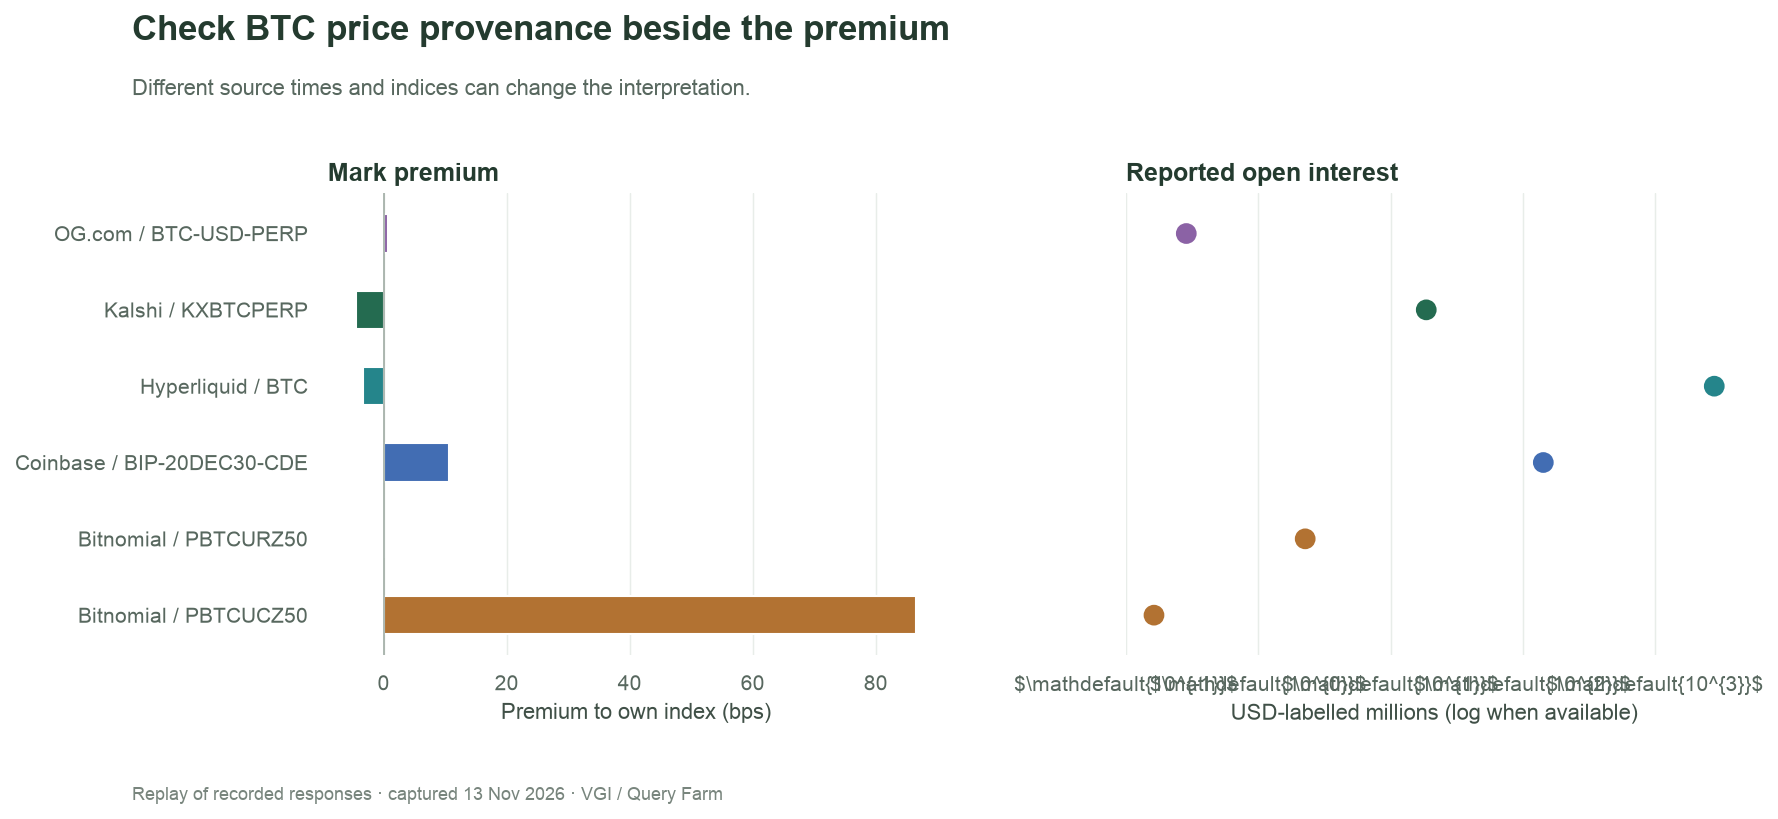

In [20]:
display(marks)
if not marks.empty:
    labels=marks.venue.map(VENUE_NAMES)+" / "+marks.symbol
    fig,axes=plt.subplots(1,2,figsize=(12,max(5.4,0.4*len(marks)+2)),sharey=True)
    y=list(range(len(marks)))
    axes[0].barh(y,marks.premium_bps,color=marks.venue.map(COLORS),height=0.5)
    axes[0].axvline(0,color="#A0ACA4",linewidth=0.8);axes[0].set_yticks(y,labels)
    axes[0].set(title="Mark premium",xlabel="Premium to own index (bps)")
    good=marks.open_interest_millions.notna() & marks.open_interest_millions.gt(0)
    if good.any():
        axes[1].scatter(marks.loc[good,"open_interest_millions"],marks.index[good],color=marks.loc[good,"venue"].map(COLORS),s=80)
        axes[1].set_xscale("log")
    else: axes[1].text(0.5,0.5,"No positive open-interest values",transform=axes[1].transAxes,ha="center")
    axes[1].set(title="Reported open interest",xlabel="USD-labelled millions (log when available)")
    for ax in axes: ax.grid(axis="y",visible=False)
    chart(fig,f"Check {asset} price provenance beside the premium","Different source times and indices can change the interpretation.")
else: prose("No marks were returned; no price comparison is available.")

In [21]:
valid=marks.dropna(subset=["premium_bps"])
if not valid.empty:
    row=valid.loc[valid.premium_bps.abs().idxmax()]
    stamp=str(row.as_of) if pd.notna(row.as_of) else "unavailable"
    prose(f"The largest absolute premium is **{row.premium_bps:+.2f} bps** for **{row.venue} / {row.symbol}**. "
          f"Its source is **{row.mark_source}**, timestamp **{stamp}**. "
          "Those fields qualify the number: an older funding mark is not a contemporaneous executable quote.")

The largest absolute premium is **+86.56 bps** for **bitnomial / PBTCUCZ50**. Its source is **last_funding_mark**, timestamp **2026-11-12 17:00:00+00:00**. Those fields qualify the number: an older funding mark is not a contemporaneous executable quote.

## Experiment: does the ranking survive a shorter window?

Change only `START_DATE` to the start of the final complete day in your current
window, keeping `END_DATE` fixed. In replay, use `START_DATE = "2026-11-12"` and
`END_DATE = "2026-11-13"`. Restart and run all cells.

**Before running:** predict whether the leading contract will stay ahead. **Watch:**
the settlement counts, sample means and largest pair difference. A changed ranking
shows sensitivity to the chosen history; an unchanged ranking does not prove the
future payment will persist. The rate callouts and chart titles update with the new
results. Restore both dates to `None` to return to the mode's default window.

The [liquidity notebook](02_liquidity_and_market_activity.ipynb) asks the next
question: how much exposure could trade at the displayed prices?

[All notebooks](README.md) · [SQL reference](https://github.com/Query-farm/vgi-perps#sql-surface) ·
[Venue mappings](https://github.com/Query-farm/vgi-perps/blob/main/docs/VENUES.md) · [Notebook standard](STANDARD.md)

The final collapsed cell releases this run's connection. Restart and run from the top after editing parameters.

In [22]:
# Cleanup · release the connection and worker
con.close()

---

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="210"></a>